# **Deel 1 - Les 4 - Oefening**

**Doel van de oefening:**
We bouwen een eenvoudige **Machine Learning Pipeline** om te voorspellen hoeveel koppen koffie een student consumeert.

**Onderwerpen in deze oefening:**
- **Preprocessing**: Imputatie (`SimpleImputer`), Schalen (`RobustScaler`), One-Hot & Ordinal Encoding, en Polynomiale interacties (`PolynomialFeatures`).
- **Regularisatie**: Oplossen van overfitting met L1 (`Lasso`) en L2 (`Ridge`).
- **Hyperparameter Tuning**: Automatisch optimaliseren via `GridSearchCV`.
- **Evaluatie**: RMSE, \(R^2\) en residual diagnostics.

## Stap 1: Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder, OrdinalEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score
import os

## Stap 2: Data

In [88]:
df = pd.read_csv("student_koffie_consumptie.csv")
df

,slaap_uren,open_tabs,uitstel_uren,studie_richting,deadline_druk,koppen_koffie
0,5.1,35,2.1,Informatica,Laag,5.7
1,9.2,21,0.3,Geneeskunde,Laag,0.0
2,7.6,16,1.8,Filosofie,Hoog,2.5
3,6.7,52,5.8,Informatica,Hoog,9.2
4,NaN,7,4.2,Filosofie,Hoog,7.4
...,...,...,...,...,...,...
445,NaN,10,4.3,Filosofie,Apocalyptisch,4.1
446,9.4,12,3.5,Rechten,Hoog,2.6
447,7.8,50,3.7,Informatica,Apocalyptisch,9.2
448,5.1,5,9.9,Geneeskunde,Laag,7.8


In [7]:
df["deadline_druk"].unique()

array(['Laag', 'Hoog', 'Matig', 'Apocalyptisch'], dtype=object)

|kolom|feature|null|type|Beschrijving|
|:---|:---|:---|:---|:---|  
|0|slaap_uren|428 non-null|float64|verwijst naar het aantal uren slaap per nacht|
|1|open_tabs|450 non-null|int64|verwijst naar het aantal geopende tabbladen in de webbrowser van de student|
|2|uitstel_uren|436 non-null|float64|verwijst naar het aantal uren dat de student uitstelgedrag vertoont bij het uitvoeren van taken|
|3|studie_richting|450 non-null|object|verwijst naar de studierichting van de student (bijvoorbeeld "Informatica", "Economie", "Psychologie", enz.)|
|4|deadline_druk|450 non-null|object|verwijst naar de mate van druk die de student ervaart bij het halen van deadlines (bijvoorbeeld "Laag", "Gemiddeld", "Hoog")|
|5|koppen_koffie|450 non-null|int64|verwijst naar het aantal koppen koffie dat de student per dag drinkt|

## Stap 3: Preprocessing

1. **Numerieke features**: Imputeren van mediaan \(\rightarrow\) `RobustScaler` (bestand tegen extreme tabs) \(\rightarrow\) optionele polynomiale interacties.
2. **Ordinale features**: Imputeren van modus \(\rightarrow\) `OrdinalEncoder` met expliciete rangorde.
3. **Nominale features**: `OneHotEncoder` (met `drop='first'` en `handle_unknown='ignore'`).

In [89]:
num_cols = ["slaap_uren", "open_tabs", "uitstel_uren"]
ord_cols = ["deadline_druk"]
nom_cols = ["studie_richting"]

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(missing_values=np.nan, strategy='median')),
    ("scaler", RobustScaler()),
    ("poly", PolynomialFeatures(degree=2, include_bias=False))
])

ord_pipeline = Pipeline([
    ("ordcorder", OrdinalEncoder())
])

nom_pipeline = Pipeline([
    ("hotcoder", OneHotEncoder(drop="first", handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", num_pipeline, num_cols),
    ("ord", ord_pipeline, ord_cols),
    ("nom", nom_pipeline, nom_cols)
])

## Stap 4: Splitsen in Train en Test

In [90]:
X_data = df[["slaap_uren","open_tabs","uitstel_uren","studie_richting","deadline_druk"]]
y_data = df["koppen_koffie"]

X = preprocessor.fit_transform(X_data)
y = y_data

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

print(f"Omvang trainingset: {X_train.shape[0]} | Omvang testset: {X_test.shape[0]}")

Omvang trainingset: 337 | Omvang testset: 113


In [91]:
feature_names = preprocessor.get_feature_names_out()

In [92]:
feature_names

array(['num__slaap_uren', 'num__open_tabs', 'num__uitstel_uren',
       'num__slaap_uren^2', 'num__slaap_uren open_tabs',
       'num__slaap_uren uitstel_uren', 'num__open_tabs^2',
       'num__open_tabs uitstel_uren', 'num__uitstel_uren^2',
       'ord__deadline_druk', 'nom__studie_richting_Geneeskunde',
       'nom__studie_richting_Informatica', 'nom__studie_richting_Rechten'],
      dtype=object)

## Stap 5: ML Pipeline

### Stap 5.1: Baseline ML Pipeline

In [93]:
lasso_pipeline = Pipeline([
    ("regressor", Lasso(alpha=0.5))
])

ridge_pipeline = Pipeline([
    ("regressor", Ridge(alpha=10.0))
])

### Stap 6.1: Baseline Training

In [94]:
lasso_pipeline.fit(X_train, y_train)
ridge_pipeline.fit(X_train, y_train)

Pipeline(steps=[('regressor', Ridge(alpha=10.0))])

### Stap 7.1: Baseline Evaluatie

In [95]:
y_pred_lasso = lasso_pipeline.predict(X_test)
y_pred_ridge = ridge_pipeline.predict(X_test)

print(f"--- Baseline LASSO Regression ---")
print(f"R² Score: {r2_score(y_test, y_pred_lasso):.3f}")
print(f"RMSE:     {np.sqrt(mean_squared_error(y_test, y_pred_lasso)):.3f}")

print(f"--- Baseline RIDGE Regression ---")
print(f"R² Score: {r2_score(y_test, y_pred_ridge):.3f}")
print(f"RMSE:     {np.sqrt(mean_squared_error(y_test, y_pred_ridge)):.3f}")

--- Baseline LASSO Regression ---
R² Score: 0.556
RMSE:     2.231
--- Baseline RIDGE Regression ---
R² Score: 0.773
RMSE:     1.595


### Stap 5.2: ML Pipeline met regularisatie en hyperparameter tuning

We testen interactietermen (`poly__degree` = 1 of 2) en optimaliseren de regularisatie-sterkte (`alpha`).
- **Ridge (L2)**: Verkleint gewichten (handig bij multicollineariteit tussen polynomiale termen).
- **Lasso (L1)**: Zet irrelevante coëfficiënten exact op 0 (automatische feature selectie).

In [98]:
# We maken een template pipeline met een instelbare estimator
pipeline = Pipeline([
    ("poly", PolynomialFeatures(include_bias=False)),
    ("regressor", Ridge())
])

param_grid = [
    {
        "poly__degree": [1, 2, 3],
        "regressor": [Ridge()],
        "regressor__alpha": [0.1, 1, 10]
    },
    {
        "poly__degree": [1, 2, 3],
        "regressor": [Lasso(max_iter=10000)],
        "regressor__alpha": [0.1, 1, 10]
    }
]

grid_model = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="neg_mean_squared_error",
    cv=5,
    verbose=1
)

grid_model.fit(X_train, y_train)

Fitting 5 folds for each of 18 candidates, totalling 90 fits


c:\Users\jamey\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.551e+01, tolerance: 3.151e-01
  model = cd_fast.enet_coordinate_descent(
c:\Users\jamey\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.810e+02, tolerance: 3.030e-01
  model = cd_fast.enet_coordinate_descent(
c:\Users\jamey\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.387e+01, toleranc

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('poly',
                                        PolynomialFeatures(include_bias=False)),
                                       ('regressor', Ridge())]),
             param_grid=[{'poly__degree': [1, 2, 3], 'regressor': [Ridge()],
                          'regressor__alpha': [0.1, 1, 10]},
                         {'poly__degree': [1, 2, 3],
                          'regressor': [Lasso(max_iter=10000)],
                          'regressor__alpha': [0.1, 1, 10]}],
             scoring='neg_mean_squared_error', verbose=1)

### Stap 6.2: Training met regularisatie en hyperparameter tuning

In [99]:
print("Best model:", grid_model.best_params_["regressor"])
print("Best polynomial degree:", grid_model.best_params_["poly__degree"])
print("Best alpha:", grid_model.best_params_["regressor__alpha"])
print("Best CV MSE:", -grid_model.best_score_)

Best model: Lasso(max_iter=10000)
Best polynomial degree: 2
Best alpha: 0.1
Best CV MSE: 1.9368686995103144


### Stap 7.2: Evaluatie met regularisatie en hyperparameter tuning

In [113]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

best_model = Pipeline([
    ("model", Lasso(alpha=0.1, max_iter=10000))
])

best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)

print("Test MSE:", mean_squared_error(y_test, y_pred))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("Test MAE:", mean_absolute_error(y_test, y_pred))
print("Test R²:", r2_score(y_test, y_pred))

Test MSE: 2.877287571672739
Test RMSE: 1.6962569297346257
Test MAE: 1.3130375540911126
Test R²: 0.7430317635317929


## Stap 7: Evaluatie

In [117]:
feature_names = preprocessor.get_feature_names_out()

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": best_model.named_steps["model"].coef_
}).sort_values("Coefficient", key=abs, ascending=False)

print(coef_df.head(50))

                             Feature  Coefficient
0                    num__slaap_uren    -3.342693
2                  num__uitstel_uren     2.173780
9                 ord__deadline_druk    -1.178926
10  nom__studie_richting_Geneeskunde     0.732457
1                     num__open_tabs     0.401854
11  nom__studie_richting_Informatica     0.248197
6                   num__open_tabs^2     0.081797
3                  num__slaap_uren^2    -0.000000
4          num__slaap_uren open_tabs    -0.000000
5       num__slaap_uren uitstel_uren    -0.000000
7        num__open_tabs uitstel_uren     0.000000
8                num__uitstel_uren^2     0.000000
12      nom__studie_richting_Rechten     0.000000


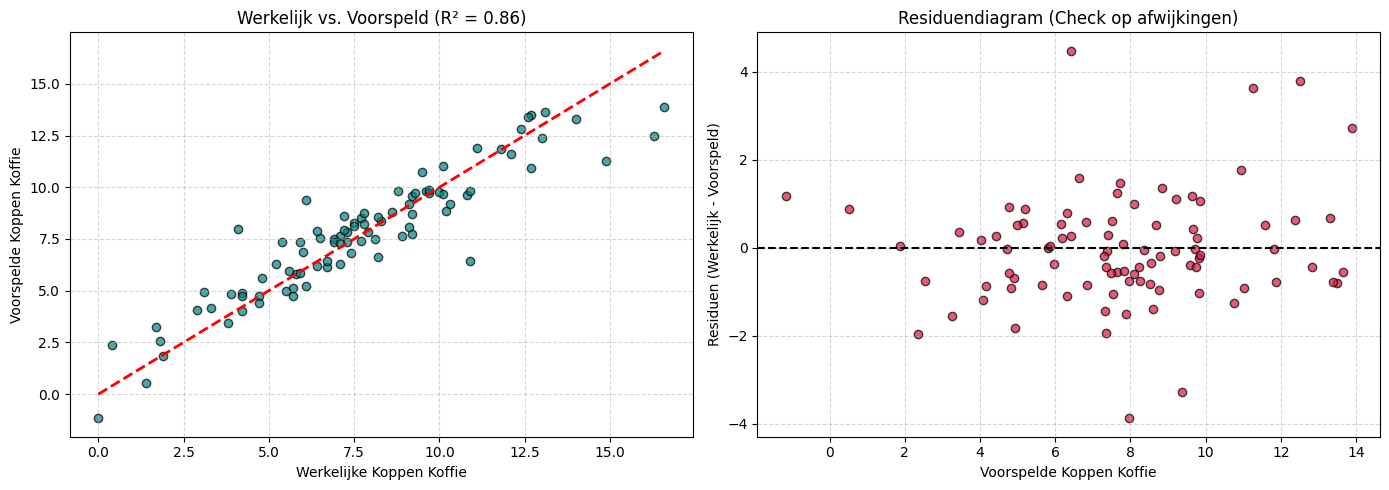

In [20]:
# Visualisatie: Werkelijk vs Voorspeld & Residuen
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Voorspeld vs Werkelijk
axes[0].scatter(y_test, y_pred_best, alpha=0.7, color='teal', edgecolors='k')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_xlabel("Werkelijke Koppen Koffie")
axes[0].set_ylabel("Voorspelde Koppen Koffie")
axes[0].set_title(f"Werkelijk vs. Voorspeld (R² = {final_r2:.2f})")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Plot 2: Residu plot (Homoscedasticiteit check)
residuals = y_test - y_pred_best
axes[1].scatter(y_pred_best, residuals, alpha=0.7, color='crimson', edgecolors='k')
axes[1].axhline(y=0, color='black', linestyle='--')
axes[1].set_xlabel("Voorspelde Koppen Koffie")
axes[1].set_ylabel("Residuen (Werkelijk - Voorspeld)")
axes[1].set_title("Residuendiagram (Check op afwijkingen)")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## Stap 8: Predictie

In [118]:
nieuwe_studenten = pd.DataFrame([
    {
        'slaap_uren': 3.0,
        'open_tabs': 85,
        'uitstel_uren': 7.5,
        'studie_richting': 'Informatica',
        'deadline_druk': 'Apocalyptisch'
    },
    {
        'slaap_uren': np.nan, # Vergeten in te vullen door uitputting
        'open_tabs': 12,
        'uitstel_uren': 1.0,
        'studie_richting': 'Filosofie',
        'deadline_druk': 'Laag'
    }
])

X_nieuw = preprocessor.transform(nieuwe_studenten)
voorspellingen = best_model.predict(X_nieuw)

for idx, p in enumerate(voorspellingen):
    print(
        f"Student {idx+1} ({nieuwe_studenten.iloc[idx]['studie_richting']}): "
        f"Verwacht koffiegebruik = {p:.1f} koppen/dag."
    )

Student 1 (Informatica): Verwacht koffiegebruik = 15.0 koppen/dag.
Student 2 (Filosofie): Verwacht koffiegebruik = 4.6 koppen/dag.


In [ ]:
X_nieuw = preprocessor.transform(nieuwe_studenten)

print("Features after preprocessing:", X_nieuw.shape[1])

Features after preprocessing: 13


In [112]:
print("Input features to polynomial step:",
      best_model.named_steps["poly"].n_features_in_)

print("Output polynomial features:",
      len(best_model.named_steps["poly"].get_feature_names_out()))

Input features to polynomial step: 13
Output polynomial features: 104


In [119]:
print(df["koppen_koffie"].describe())

count    450.000000
mean       7.330222
std        3.366218
min        0.000000
25%        5.000000
50%        7.200000
75%        9.500000
max       16.600000
Name: koppen_koffie, dtype: float64
